# 05. Clustering and Probabilistic Mixture Models

**Research question RQ2.** Do distinct engagement profiles exist among students at day 28, and do their risk levels differ?

**Design rules**

- **Unsupervised on behaviour only.** Clusters are built from how students used the platform in the first 28 days (engagement relative to the module, regularity, activity mix). Outcome, background (education, deprivation, age, disability, gender) and assessment results are **not** used to form clusters; they are used afterwards to *describe* them.
- **Fitted on the 2013 training years only.** The 2014 students are only *assigned* to the fitted clusters, using features alone. No 2014 labels are used here.
- **Students with no clicks at all** (3.4%) have nothing to cluster. They form their own rule-based "no activity" group and are excluded from the fit.
- **Module-relative behaviour.** Every clustering feature is a rank among the active students of the *same module-presentation*, so that clusters describe how a student behaves compared with peers, not which course they took (a first attempt on raw features failed this test; see section 1.3).
- **Standardise, then PCA** (keep 90% of the variance) so that correlated engagement features do not dominate the distances.
- **Four methods from the course:** k-means, hierarchical (Ward), DBSCAN and Gaussian mixture models (GMM/EM).

**Pre-stated rule for choosing k** (set before looking at the results)

1. Candidate k are 3 to 8.
2. Every cluster must contain at least 5% of the students.
3. Bootstrap stability must be adequate: mean adjusted Rand index (ARI) of at least 0.6.
4. Among the candidates passing 2 and 3, take the smallest k after which one more mixture component improves the BIC by less than 2% of the total BIC improvement. Interpretability is then checked, not optimised.
5. *Clause added after the first run*, which showed that rules 1 to 4 had a gap: if no passing candidate reaches the BIC elbow, use the largest k that passes rules 2 and 3. The first run ended in exactly that situation, so the clause was written down before the corrected features were clustered.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf

RANDOM_STATE = 42
PROC, OUT = Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = ["code_module", "code_presentation", "id_student"]

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # fixed categorical slots 1 to 4
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

feat = pd.read_csv(PROC / "oulad_features_day28.csv")
spec = json.loads((OUT / "feature_groups.json").read_text())
train = feat[feat.split == "train"].reset_index(drop=True)
test = feat[feat.split == "test"].reset_index(drop=True)
print(f"train {len(train):,} rows | test {len(test):,} rows")

train 11,818 rows | test 15,735 rows


## 1. Clustering features

In [2]:
MP = ["code_module", "code_presentation"]
# First attempt: raw behavioural features (kept for the diagnostic in section 1.3)
RAW_CL = ["eng_pct_poststart_days", "eng_pct_sites", "eng_pct_clicks", "max_gap_poststart", "trend_slope", "prestart_share",
          "log_clicks_per_active_day", "share_forumng", "share_oucontent", "share_homepage", "share_quiz", "share_subpage"]
# Module-relative version: rank each behaviour among the ACTIVE students of the same module-presentation (like eng_pct_* from notebook 04)
REL_SRC = ["max_gap_poststart", "trend_slope", "prestart_share", "log_clicks_per_active_day", "share_forumng", "share_oucontent",
           "share_homepage", "share_quiz", "share_subpage"]
def add_relative(df):
    df = df.copy(); act = df.no_vle_activity == 0
    for c in REL_SRC:
        df[f"rel_{c}"] = np.nan
        df.loc[act, f"rel_{c}"] = df[act].groupby(MP)[c].rank(pct=True)
    return df
train, test = add_relative(train), add_relative(test)
CL_FEATS = ["eng_pct_poststart_days", "eng_pct_sites", "eng_pct_clicks"] + [f"rel_{c}" for c in REL_SRC]

inactive_tr = train.no_vle_activity == 1
inactive_te = test.no_vle_activity == 1
for df, ina in ((train, inactive_tr), (test, inactive_te)):
    assert df.loc[~ina, CL_FEATS + RAW_CL].isna().sum().sum() == 0, "missing values in clustering features of active students"
print(f"no-activity students: train {inactive_tr.sum():,} ({inactive_tr.mean():.1%}) | test {inactive_te.sum():,} ({inactive_te.mean():.1%})")
fit_df = train[~inactive_tr].reset_index(drop=True)
print(f"clustering fit set: {len(fit_df):,} students, {len(CL_FEATS)} features")

# Which features are redundant? (largest pairwise correlations)
rho = fit_df[CL_FEATS].corr(method="spearman")
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("rho").to_frame()
display(pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(8))

no-activity students: train 457 (3.9%) | test 483 (3.1%)
clustering fit set: 11,361 students, 12 features


rho
eng_pct_poststart_days rel_max_gap_poststart         -0.898
                       eng_pct_clicks                 0.859
eng_pct_sites          eng_pct_clicks                 0.852
eng_pct_clicks         rel_max_gap_poststart         -0.764
eng_pct_poststart_days eng_pct_sites                  0.720
eng_pct_clicks         rel_log_clicks_per_active_day  0.688
eng_pct_sites          rel_max_gap_poststart         -0.647
                       rel_log_clicks_per_active_day  0.600

In [3]:
scaler = StandardScaler().fit(fit_df[CL_FEATS])
Xs = scaler.transform(fit_df[CL_FEATS])
pca = PCA(n_components=0.90, random_state=RANDOM_STATE).fit(Xs)
Z = pca.transform(Xs)
print(f"{pca.n_components_} principal components keep {pca.explained_variance_ratio_.sum():.1%} of the variance")
print("variance explained per component:", np.round(pca.explained_variance_ratio_, 3))
load = pd.DataFrame(pca.components_.T, index=CL_FEATS, columns=[f"PC{i + 1}" for i in range(pca.n_components_)])
display(load.round(2))

7 principal components keep 90.8% of the variance
variance explained per component: [0.344 0.129 0.117 0.089 0.085 0.074 0.07 ]


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
eng_pct_poststart_days,0.440,-0.090,0.170,0.170,-0.190,-0.180,-0.080
eng_pct_sites,0.420,0.200,0.230,-0.070,0.050,0.100,-0.110
eng_pct_clicks,0.480,0.060,0.080,-0.010,-0.030,0.060,0.010
rel_max_gap_poststart,-0.410,0.100,-0.190,-0.160,0.190,0.250,0.060
rel_trend_slope,-0.050,0.190,-0.100,0.660,-0.230,0.630,-0.220
rel_prestart_share,0.080,-0.210,0.440,-0.180,0.280,0.570,0.500
rel_log_clicks_per_active_day,0.320,0.330,-0.230,-0.200,0.120,0.210,-0.040
rel_share_forumng,0.270,-0.380,-0.420,-0.210,-0.140,0.160,-0.020
rel_share_oucontent,-0.080,0.470,0.170,0.040,-0.500,-0.150,0.580
rel_share_homepage,-0.130,-0.410,0.510,0.260,-0.020,-0.070,-0.170


**Observed.** Seven principal components keep 90.8% of the variance. The first (34%) is overall volume and regularity: clicks, active days and distinct sites load positively and the longest inactive stretch negatively. The strongest pairwise link is between active days and the longest gap (Spearman -0.90), and between active days and clicks (0.86).
**Why it matters.** The features are strongly redundant, which is why the clusters are built in PCA space instead of on the raw features, and why most of the structure is expected to lie along one axis (how much and how regularly students work).

### 1.3 Diagnostic: why module-relative features? (first attempt vs final)

The first attempt clustered the *raw* behaviours (activity mix, gaps, trend, intensity). Activity mix and regularity depend on how each course is designed, so such clusters can end up describing **modules** and not **students**.
This diagnostic fits the same mixture model (k = 6, for illustration only) on both feature sets and measures (a) how strongly the clusters coincide with modules (Cramer's V; 0 = not at all, 1 = identical) and (b) how much the share of students in each cluster moves between the 2013 fit and the 2014 assignment (population stability index, PSI).

In [4]:
def cramers_v_table(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]; n_ = ct.values.sum(); r, c = ct.shape
    return float(np.sqrt(max(0, chi2 / n_ - (r - 1) * (c - 1) / (n_ - 1)) / min(r - 1, c - 1)))

def quick_profile(cols, k=6):
    te_act = test[~inactive_te]
    sc_ = StandardScaler().fit(fit_df[cols]); pc_ = PCA(n_components=0.90, random_state=RANDOM_STATE).fit(sc_.transform(fit_df[cols]))
    Zq = pc_.transform(sc_.transform(fit_df[cols]))
    gq = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(Zq)
    lab_tr, lab_te = gq.predict(Zq), gq.predict(pc_.transform(sc_.transform(te_act[cols])))
    p13 = np.bincount(lab_tr, minlength=k) / len(lab_tr); p14 = np.bincount(lab_te, minlength=k) / len(lab_te)
    psi = float(np.sum((p14 - p13) * np.log((p14 + 1e-9) / (p13 + 1e-9))))
    v = cramers_v_table(pd.crosstab(lab_tr, fit_df.code_module))
    top_module_share = pd.crosstab(lab_tr, fit_df.code_module, normalize="index").max(axis=1).mean()
    return dict(components=pc_.n_components_, cramers_v_cluster_vs_module=v, mean_share_of_main_module_in_cluster=top_module_share, psi_2013_vs_2014=psi)

diag = pd.DataFrame({"raw behaviours": quick_profile(RAW_CL), "module-relative behaviours": quick_profile(CL_FEATS)}).T
diag

,components,cramers_v_cluster_vs_module,mean_share_of_main_module_in_cluster,psi_2013_vs_2014
raw behaviours,7.000,0.522,0.630,0.454
module-relative behaviours,7.000,0.173,0.353,0.010


**Observed.** On raw behaviours the clusters coincide strongly with modules (Cramer's V 0.52; on average 63% of a cluster comes from one module) and their sizes move a lot between the 2013 fit and the 2014 assignment (PSI 0.45, because the unseen module CCC piles into one cluster). On module-relative behaviours the link to module falls to V 0.17 (35% from the main module) and the share shift disappears (PSI 0.01).
**Why it matters.** The first attempt would have reported "student types" that were really courses. Ranking each behaviour within its own module-presentation is what makes the profiles describe students.
**Action.** Use the module-relative features for everything below.

## 2. How many clusters? k-means, GMM and their stability

In [5]:
KS = list(range(2, 10))
rng_sil = dict(sample_size=4000, random_state=RANDOM_STATE)
rows = []
km_ref = {}
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    km_ref[k] = km.labels_
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Z, km.labels_, **rng_sil),
                     calinski_harabasz=calinski_harabasz_score(Z, km.labels_), davies_bouldin=davies_bouldin_score(Z, km.labels_)))
km_table = pd.DataFrame(rows).set_index("k")
display(km_table)

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,"90,709.941",0.237,"4,141.565",1.617
3,"82,082.709",0.172,"2,885.128",2.048
4,"76,099.578",0.151,"2,372.092",1.976
5,"71,512.911",0.134,"2,075.099",1.912
6,"67,990.509",0.132,"1,863.591",1.964
7,"64,758.218",0.135,"1,724.815",1.875
8,"62,461.854",0.129,"1,592.246",1.868
9,"60,425.128",0.122,"1,487.882",1.866


In [6]:
COV_TYPES = ["full", "tied", "diag", "spherical"]
bic = pd.DataFrame(index=range(1, 11), columns=COV_TYPES, dtype=float)
for cov in COV_TYPES:
    for k in bic.index:
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, random_state=RANDOM_STATE).fit(Z)
        bic.loc[k, cov] = g.bic(Z)
display(bic.round(0))
print("lowest BIC by covariance type (k):", {c: int(bic[c].idxmin()) for c in COV_TYPES})

,full,tied,diag,spherical
1,"248,511.000","248,511.000","248,315.000","260,948.000"
2,"245,765.000","247,437.000","246,577.000","248,917.000"
3,"244,975.000","246,873.000","245,848.000","247,767.000"
4,"244,270.000","246,808.000","245,541.000","247,010.000"
5,"243,163.000","245,120.000","245,285.000","246,383.000"
6,"242,008.000","245,426.000","244,918.000","245,991.000"
7,"241,583.000","243,947.000","244,592.000","245,548.000"
8,"240,690.000","243,926.000","244,302.000","245,322.000"
9,"238,193.000","244,150.000","244,192.000","245,072.000"
10,"237,473.000","243,746.000","243,425.000","244,796.000"


lowest BIC by covariance type (k): {'full': 10, 'tied': 10, 'diag': 10, 'spherical': 10}


In [7]:
# Fit the 'full' GMM for every candidate k, record cluster sizes and bootstrap stability
gmm_ref, gmm_lab = {}, {}
for k in KS:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=RANDOM_STATE).fit(Z)
    gmm_ref[k] = g; gmm_lab[k] = g.predict(Z)

def boot_ari(fit_fn, ref_labels, B=20, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed); out = []
    for b in range(B):
        idx = rng.randint(0, len(Z), len(Z))
        out.append(adjusted_rand_score(ref_labels, fit_fn(b, Z[idx]).predict(Z)))
    return float(np.mean(out)), float(np.std(out))

rows = []
for k in KS:
    km_s = boot_ari(lambda b, Zb, k=k: KMeans(n_clusters=k, n_init=3, random_state=b).fit(Zb), km_ref[k])
    gm_s = boot_ari(lambda b, Zb, k=k: GaussianMixture(n_components=k, covariance_type="full", n_init=1, random_state=b).fit(Zb), gmm_lab[k])
    rows.append(dict(k=k, kmeans_stability=km_s[0], kmeans_sd=km_s[1], gmm_stability=gm_s[0], gmm_sd=gm_s[1],
                     gmm_smallest_share=np.bincount(gmm_lab[k]).min() / len(Z), kmeans_smallest_share=np.bincount(km_ref[k]).min() / len(Z),
                     gmm_silhouette=silhouette_score(Z, gmm_lab[k], **rng_sil), gmm_bic=bic.loc[k, "full"]))
sel = pd.DataFrame(rows).set_index("k")
display(sel)

,kmeans_stability,kmeans_sd,gmm_stability,gmm_sd,gmm_smallest_share,kmeans_smallest_share,gmm_silhouette,gmm_bic
k,,,,,,,,
2,0.980,0.009,0.956,0.013,0.486,0.479,0.221,"245,765.294"
3,0.935,0.044,0.899,0.031,0.256,0.277,0.164,"244,975.121"
4,0.785,0.130,0.538,0.160,0.151,0.193,0.137,"244,269.640"
5,0.765,0.138,0.466,0.136,0.135,0.149,0.103,"243,162.844"
6,0.716,0.139,0.290,0.098,0.086,0.120,0.064,"242,007.697"
7,0.797,0.117,0.233,0.073,0.053,0.095,0.056,"241,583.402"
8,0.655,0.143,0.264,0.128,0.058,0.092,0.048,"240,690.387"
9,0.625,0.088,0.301,0.071,0.043,0.081,0.020,"238,192.831"


total BIC drop (k=1 to best): 11,038 | 2% threshold: 221
BIC gain from adding one more component: {1: 2746, 2: 790, 3: 705, 4: 1107, 5: 1155, 6: 424, 7: 893, 8: 2498, 9: 720}
first k whose next component gains less than 2%: 10
k passing the size and stability rules (GMM): [3]
==> chosen k = 3


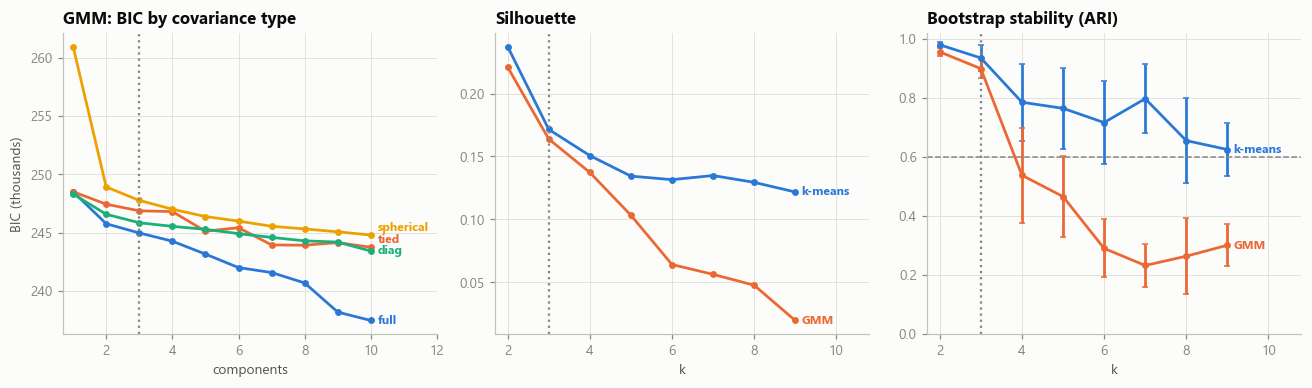

In [8]:
# Apply the pre-stated rule
b = bic["full"]
total_drop = b.iloc[0] - b.min()
gain_next = (b - b.shift(-1))                        # BIC improvement from adding one more component
elbow_k = int(next((k for k in b.index if k >= 2 and gain_next.get(k, 0) < 0.02 * total_drop), b.index.max()))
ok = sel[(sel.index >= 3) & (sel.index <= 8) & (sel.gmm_smallest_share >= 0.05) & (sel.gmm_stability >= 0.6)]
print(f"total BIC drop (k=1 to best): {total_drop:,.0f} | 2% threshold: {0.02 * total_drop:,.0f}")
print("BIC gain from adding one more component:", gain_next.round(0).dropna().astype(int).to_dict())
print(f"first k whose next component gains less than 2%: {elbow_k}")
print("k passing the size and stability rules (GMM):", list(ok.index))
K = int(min([k for k in ok.index if k >= elbow_k], default=ok.index.max()))
print(f"==> chosen k = {K}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
ends = []
for cov, col in zip(COV_TYPES, (C1, C2, C3, C4)):
    ax.plot(bic.index, bic[cov] / 1000, "-o", color=col, linewidth=1.8, markersize=3.5)
    ends.append((bic[cov].iloc[-1] / 1000, cov, col))
ypos = []
for v_, _, _ in sorted(ends):
    ypos.append(v_ if not ypos else max(v_, ypos[-1] + 1.0))      # keep labels at least 1 unit apart
for (v_, cov, col), y_ in zip(sorted(ends), ypos):
    ax.text(10.2, y_, cov, color=col, fontsize=8, va="center", fontweight="bold")
ax.axvline(K, color=MUTED, linestyle=":"); ax.set_xlim(0.7, 12); ax.set_xlabel("components"); ax.set_ylabel("BIC (thousands)"); ax.set_title("GMM: BIC by covariance type")
ax = axes[1]
ax.plot(km_table.index, km_table.silhouette, "-o", color=C1, linewidth=1.8, markersize=3.5); ax.plot(sel.index, sel.gmm_silhouette, "-o", color=C2, linewidth=1.8, markersize=3.5)
ax.text(9.15, km_table.silhouette.iloc[-1], "k-means", color=C1, fontsize=8, va="center", fontweight="bold"); ax.text(9.15, sel.gmm_silhouette.iloc[-1], "GMM", color=C2, fontsize=8, va="center", fontweight="bold")
ax.axvline(K, color=MUTED, linestyle=":"); ax.set_xlim(1.7, 10.8); ax.set_xlabel("k"); ax.set_title("Silhouette")
ax = axes[2]
ax.errorbar(sel.index, sel.kmeans_stability, yerr=sel.kmeans_sd, color=C1, marker="o", markersize=3.5, linewidth=1.8, capsize=2)
ax.errorbar(sel.index, sel.gmm_stability, yerr=sel.gmm_sd, color=C2, marker="o", markersize=3.5, linewidth=1.8, capsize=2)
ax.text(9.15, sel.kmeans_stability.iloc[-1], "k-means", color=C1, fontsize=8, va="center", fontweight="bold"); ax.text(9.15, sel.gmm_stability.iloc[-1], "GMM", color=C2, fontsize=8, va="center", fontweight="bold")
ax.axhline(0.6, color=MUTED, linestyle="--", linewidth=1); ax.axvline(K, color=MUTED, linestyle=":"); ax.set_xlim(1.7, 10.8); ax.set_ylim(0, 1.02)
ax.set_xlabel("k"); ax.set_title("Bootstrap stability (ARI)")
fig.tight_layout(); savefig(fig, "05_k_selection.png"); plt.show()

**Observed.** The structure is weak. Silhouette scores are low everywhere (0.24 for two clusters and 0.17 for three for k-means; 0.22 and 0.16 for GMM, about 0.06 or less from six clusters on), and values under 0.25 are conventionally read as no substantial structure. The BIC falls slowly and never levels off within ten components; its largest single gain is from one to two components (2,746 of the total 11,038 drop).
Stability tells the same story: GMM is stable at k = 2 and 3 (ARI 0.96 and 0.90), then collapses (0.54 at k = 4, 0.29 at k = 6). k-means stays above 0.6 for every k, but that only shows that slicing a continuous cloud is repeatable, not that the slices are real groups.
The pre-stated rules leave exactly one candidate: **k = 3** (smallest cluster 26%, stability 0.90). The BIC elbow rule never triggered before k = 10, so the clause added to the rules decided it.
**Why it matters.** Engagement at day 28 is better described as a continuum with a low, a middle and a high region than as separate student types.

## 3. DBSCAN and hierarchical clustering as cross-checks

,clusters,noise_share,largest_cluster_share,silhouette_non_noise
eps,,,,
0.400,2,0.996,0.002,0.894
0.600,3,0.995,0.003,0.830
0.800,5,0.989,0.004,0.482
1.000,18,0.842,0.112,-0.002
1.300,7,0.154,0.836,-0.019
1.600,1,0.011,0.989,NaN
2.000,1,0.000,1.000,NaN
2.500,1,0.000,1.000,NaN


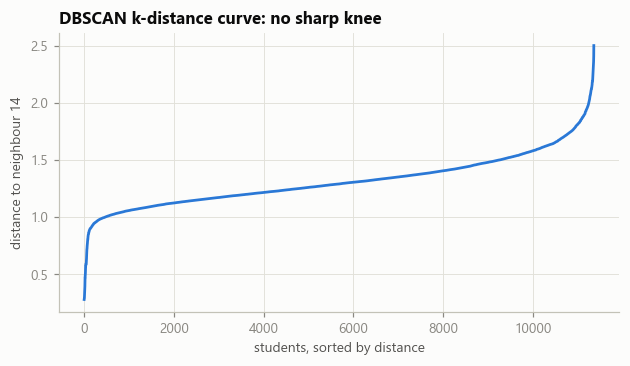

In [9]:
min_samples = 2 * Z.shape[1]
rows = []
for eps in (0.4, 0.6, 0.8, 1.0, 1.3, 1.6, 2.0, 2.5):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Z)
    core = lab >= 0
    n_cl = len(set(lab[core]))
    sil = silhouette_score(Z[core], lab[core], sample_size=min(4000, int(core.sum())), random_state=RANDOM_STATE) if n_cl > 1 else np.nan
    rows.append(dict(eps=eps, clusters=n_cl, noise_share=1 - core.mean(), largest_cluster_share=(np.bincount(lab[core]).max() / len(Z)) if n_cl else 0, silhouette_non_noise=sil))
dbs = pd.DataFrame(rows).set_index("eps")
display(dbs)

nn = NearestNeighbors(n_neighbors=min_samples).fit(Z)
kd = np.sort(nn.kneighbors(Z)[0][:, -1])
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(np.arange(len(kd)), kd, color=C1, linewidth=1.8); ax.set_xlabel("students, sorted by distance"); ax.set_ylabel(f"distance to neighbour {min_samples}")
ax.set_title("DBSCAN k-distance curve: no sharp knee")
fig.tight_layout(); savefig(fig, "05_dbscan_kdistance.png"); plt.show()

Agreement between methods at k = 3 (adjusted Rand index, 5,000-student subsample):


,k-means,GMM,Ward
k-means,1.000,0.613,0.386
GMM,0.613,1.000,0.312
Ward,0.386,0.312,1.000


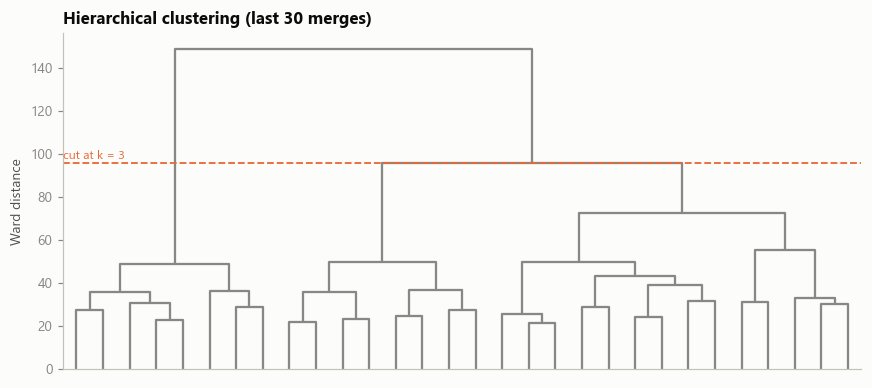

In [10]:
# Ward hierarchical clustering on a random subsample (the distance matrix is quadratic in n)
rs = np.random.RandomState(RANDOM_STATE)
sub = rs.choice(len(Z), size=5000, replace=False)
Zs = Z[sub]
L = linkage(Zs, method="ward")
ward_lab = fcluster(L, t=K, criterion="maxclust") - 1
km_sub = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(Zs)
gmm_sub = gmm_ref[K].predict(Zs)
agree = pd.DataFrame({"k-means": [1, adjusted_rand_score(km_sub, gmm_sub), adjusted_rand_score(km_sub, ward_lab)],
                      "GMM": [adjusted_rand_score(km_sub, gmm_sub), 1, adjusted_rand_score(gmm_sub, ward_lab)],
                      "Ward": [adjusted_rand_score(km_sub, ward_lab), adjusted_rand_score(gmm_sub, ward_lab), 1]}, index=["k-means", "GMM", "Ward"])
print(f"Agreement between methods at k = {K} (adjusted Rand index, 5,000-student subsample):"); display(agree)

fig, ax = plt.subplots(figsize=(8, 3.6))
dendrogram(L, truncate_mode="lastp", p=30, no_labels=True, color_threshold=0, above_threshold_color=MUTED, ax=ax)
cut = L[-(K - 1), 2] * 0.999
ax.axhline(cut, color=C2, linestyle="--", linewidth=1.2); ax.text(0, cut * 1.02, f"cut at k = {K}", color=C2, fontsize=8)
ax.set_ylabel("Ward distance"); ax.set_title("Hierarchical clustering (last 30 merges)"); ax.grid(False)
fig.tight_layout(); savefig(fig, "05_dendrogram.png"); plt.show()

**Observed.** DBSCAN finds no density gaps. Where it finds several clusters, most students are labelled noise (84% noise at eps 1.0 with a silhouette near 0), or one cluster holds 84% to 100% of the students (eps 1.3 and above). The k-distance curve rises smoothly without a knee. Ward hierarchical clustering at k = 3 agrees only moderately with the mixture and k-means solutions (ARI 0.39 and 0.31; k-means against GMM 0.61).
**Why it matters.** Four different methods, four different boundaries: the exact cut points depend on the method. What is common to all is a low-to-high gradient of engagement. The mixture model is kept as the final model because it gives each student a probability of belonging to every profile, which suits boundaries that are not sharp.

## 4. Final model: Gaussian mixture, profiles and soft assignment

In [11]:
g = gmm_ref[K]
raw_lab = g.predict(Z)
order = pd.Series(fit_df.groupby(raw_lab).eng_pct_poststart_days.mean()).sort_values().index    # cluster 1 = least engaged
remap = {old: new + 1 for new, old in enumerate(order)}
fit_df["cluster"] = [remap[l] for l in raw_lab]
post = g.predict_proba(Z)[:, list(order)]
for j in range(K): fit_df[f"p_c{j + 1}"] = post[:, j]
fit_df["max_posterior"] = post.max(axis=1)

print("cluster sizes (share of the clustered students):"); print(fit_df.cluster.value_counts(normalize=True).sort_index().round(3).to_string())
print(f"\nposterior certainty: mean {fit_df.max_posterior.mean():.2f}; share of students with a posterior above 0.9: {(fit_df.max_posterior > 0.9).mean():.1%}; below 0.6: {(fit_df.max_posterior < 0.6).mean():.1%}")
print("log-likelihood per student:", round(g.score(Z), 3), "| converged:", g.converged_)

cluster sizes (share of the clustered students):
cluster
1   0.256
2   0.309
3   0.434

posterior certainty: mean 0.85; share of students with a posterior above 0.9: 54.9%; below 0.6: 11.6%
log-likelihood per student: -10.737 | converged: True


**Observed.** The three profiles contain 25.6%, 30.9% and 43.4% of the active students. The mean assignment certainty is 0.85; 54.9% of students have a posterior above 0.9, and 11.6% sit below 0.6 (students near a boundary).

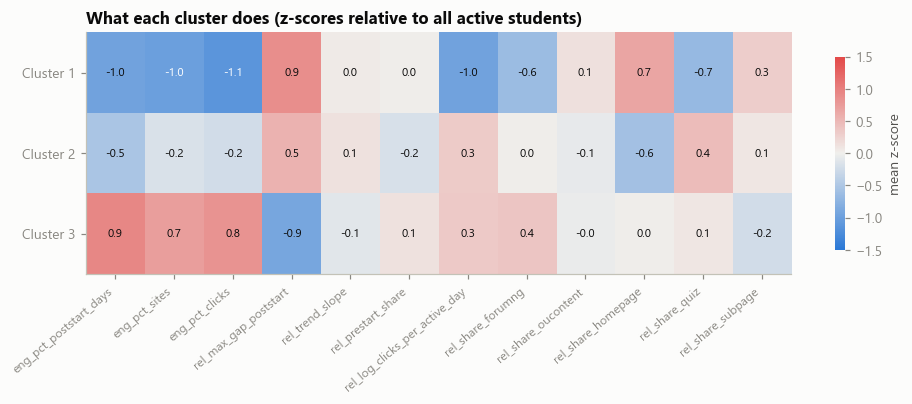

,eng_pct_poststart_days,eng_pct_sites,eng_pct_clicks,max_gap_poststart,trend_slope,prestart_share,log_clicks_per_active_day,share_forumng,share_oucontent,share_homepage,share_quiz,share_subpage,median_clicks
cluster,,,,,,,,,,,,,
1,0.250,0.240,0.210,12.360,-0.000,0.260,2.410,0.160,0.190,0.330,0.010,0.170,75.000
2,0.370,0.470,0.450,9.260,0.050,0.180,3.120,0.280,0.170,0.190,0.100,0.140,220.000
3,0.780,0.720,0.750,3.540,-0.080,0.210,3.110,0.320,0.160,0.240,0.050,0.120,490.000


In [12]:
# Profile 1: behaviour. Mean standardised value of each clustering feature by cluster, and original-scale means.
zprof = pd.DataFrame(Xs, columns=CL_FEATS).groupby(fit_df.cluster.values).mean()
fig, ax = plt.subplots(figsize=(9, 0.45 * K + 2.4))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
im = ax.imshow(zprof.values, cmap=cmap, vmin=-1.5, vmax=1.5, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(CL_FEATS)), CL_FEATS, rotation=40, ha="right", fontsize=8); ax.set_yticks(range(K), [f"Cluster {c}" for c in zprof.index])
for i in range(zprof.shape[0]):
    for j in range(zprof.shape[1]):
        v = zprof.values[i, j]; ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color=INK if abs(v) < 1.0 else "#ffffff")
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("mean z-score"); cb.outline.set_visible(False)
ax.set_title("What each cluster does (z-scores relative to all active students)")
fig.tight_layout(); savefig(fig, "05_cluster_heatmap.png"); plt.show()

orig = fit_df.groupby("cluster")[RAW_CL].mean()      # the same behaviours in their original units, for interpretation
orig["median_clicks"] = np.expm1(fit_df.groupby("cluster").log_clicks_total.median())
display(orig.round(2))

**Observed (profile 1: behaviour).** The profiles are ordered mainly by volume and regularity (z-scores relative to the active students):

- **Cluster 1, low engagement (26%).** About one standard deviation below average on days, sites and clicks, with long silences (mean longest gap 12.4 days, median 75 clicks) and a homepage-heavy, quiz-light mix.
- **Cluster 2, intermittent (31%).** Slightly below average on volume (z -0.5 to -0.2), long gaps (9.3 days), but as intense as the sustained cluster on the days they are active (z +0.3 clicks per active day) and with more quiz use (z +0.4).
- **Cluster 3, sustained (43%).** About 0.8 standard deviations above average on volume, short gaps (3.5 days), median 490 clicks, slightly more forum use.

Differences in activity mix are small (|z| of 0.7 or less) once everything is ranked within module, so what separates the profiles is how much and how regularly students study, not what they study.

In [13]:
# Profile 2: assessment behaviour, background, module mix (descriptive only, none of these formed the clusters)
ass = fit_df.groupby("cluster").agg(n=("id_student", "size"), submit_rate_early=("submit_rate_early", "mean"), score_pct_mean=("score_pct_mean", "mean"),
                                     days_before_due_mean=("days_before_due_mean", "mean"), edu_level=("edu_level", "mean"), imd_order=("imd_order", "mean"),
                                     num_prev=("num_prev_capped", "mean"), disability_share=("disab", "mean"), male_share=("male", "mean"))
ass["share_of_clustered"] = ass.n / ass.n.sum()
display(ass.round(3))
mod_mix = pd.crosstab(fit_df.cluster, fit_df.code_module, normalize="index").mul(100).round(1)
print("module mix within each cluster (% of the cluster):"); display(mod_mix)
ct = pd.crosstab(fit_df.cluster, fit_df.code_module)
chi2 = stats.chi2_contingency(ct, correction=False)[0]; n_ = ct.values.sum(); r, c = ct.shape
v = np.sqrt(max(0, chi2 / n_ - (r - 1) * (c - 1) / (n_ - 1)) / min(r - 1, c - 1))
print(f"association between cluster and module: Cramer's V approx {v:.3f} (0 means clusters are not just modules)")

,n,submit_rate_early,score_pct_mean,days_before_due_mean,edu_level,imd_order,num_prev,disability_share,male_share,share_of_clustered
cluster,,,,,,,,,,
1,2914,0.731,0.407,0.740,1.689,4.057,0.255,0.102,0.541,0.256
2,3515,0.884,0.470,16.808,1.754,4.273,0.166,0.087,0.526,0.309
3,4932,0.979,0.555,16.289,1.742,4.446,0.114,0.097,0.509,0.434


module mix within each cluster (% of the cluster):


code_module,AAA,BBB,DDD,EEE,FFF,GGG
cluster,,,,,,
1,3.700,26.700,26.100,3.100,32.800,7.600
2,2.900,29.400,21.900,11.300,29.100,5.400
3,3.200,27.400,24.500,8.300,28.600,8.000


association between cluster and module: Cramer's V approx 0.089 (0 means clusters are not just modules)


**Observed (profile 2: assessment, background, modules).** Early assessment behaviour rises with engagement: the share of due assessments submitted goes 0.73, 0.88, 0.98 and the mean score rank 0.41, 0.47, 0.56. Cluster 1 submits at the deadline (0.7 days early on average) while clusters 2 and 3 submit about 16 to 17 days early.
Background barely differs across the profiles (mean education level 1.69, 1.75, 1.74; disability 10%, 9%, 10%; male 54%, 53%, 51%), with a modest gradient for deprivation (mean IMD band 4.06, 4.27, 4.45) and prior attempts (0.26, 0.17, 0.11). The modules are spread almost evenly (Cramer's V 0.09).
**Why it matters.** The profiles are not just proxies for background or course, and none of these variables was used to form them.

,n,at_risk,rate,lo,hi
cluster (0 = no activity),,,,,
0,457,369,0.807,0.769,0.841
1,2914,1827,0.627,0.609,0.644
2,3515,1634,0.465,0.448,0.481
3,4932,1418,0.288,0.275,0.300


chi-square on clusters x at-risk: Cramer's V = 0.280 | spread in at-risk rate: 28.8% to 62.7%

Four outcomes by cluster (% of cluster):


target_final_result,Distinction,Pass,Fail,Withdrawn
cluster,,,,
1,3.500,33.800,39.500,23.200
2,6.400,47.100,29.000,17.500
3,15.000,56.200,16.000,12.800


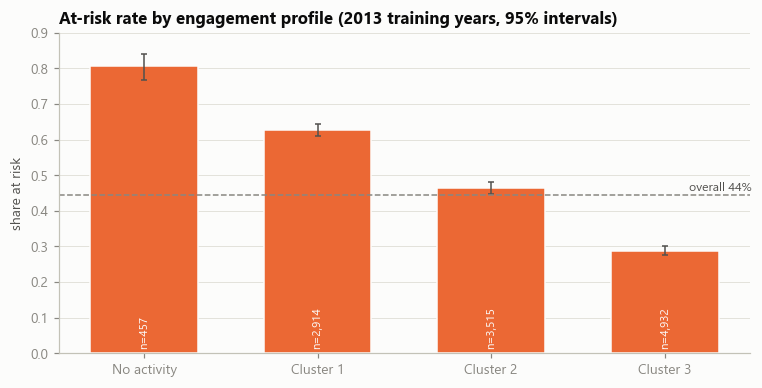

In [14]:
# Profile 3: risk. Training labels only.
def rate(df):
    g_ = df.groupby("cluster").target_at_risk.agg(n="size", at_risk="sum"); g_["rate"] = g_.at_risk / g_.n
    g_["lo"], g_["hi"] = proportion_confint(g_.at_risk, g_.n, method="wilson"); return g_
risk = rate(fit_df)
none_row = pd.DataFrame({"n": [int(inactive_tr.sum())], "at_risk": [int(train.loc[inactive_tr, "target_at_risk"].sum())]}, index=[0])
none_row["rate"] = none_row.at_risk / none_row.n; none_row["lo"], none_row["hi"] = proportion_confint(none_row.at_risk, none_row.n, method="wilson")
risk_all = pd.concat([none_row, risk]); risk_all.index.name = "cluster (0 = no activity)"
display(risk_all)
ct = pd.crosstab(fit_df.cluster, fit_df.target_at_risk)
chi2 = stats.chi2_contingency(ct, correction=False)[0]; n_ = ct.values.sum()
print(f"chi-square on clusters x at-risk: Cramer's V = {np.sqrt(chi2 / n_):.3f} | spread in at-risk rate: {risk.rate.min():.1%} to {risk.rate.max():.1%}")
print("\nFour outcomes by cluster (% of cluster):")
display(pd.crosstab(fit_df.cluster, fit_df.target_final_result, normalize="index").mul(100).round(1)[["Distinction", "Pass", "Fail", "Withdrawn"]])

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(risk_all)); ax.bar(x, risk_all.rate, width=0.62, color=C2, edgecolor=SURFACE)
ax.errorbar(x, risk_all.rate, yerr=[risk_all.rate - risk_all.lo, risk_all.hi - risk_all.rate], fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
ax.axhline(train.target_at_risk.mean(), color=MUTED, linestyle="--", linewidth=1); ax.text(len(x) - 0.5, train.target_at_risk.mean() + 0.012, f"overall {train.target_at_risk.mean():.0%}", ha="right", color=INK2, fontsize=8)
ax.set_xticks(x, ["No activity"] + [f"Cluster {c}" for c in risk.index]); ax.set_ylabel("share at risk"); ax.set_ylim(0, 0.9); ax.grid(axis="x", visible=False)
for xi, n_c in zip(x, risk_all.n): ax.text(xi, 0.02, f"n={n_c:,}", ha="center", fontsize=7.5, color=SURFACE, rotation=90)
ax.set_title("At-risk rate by engagement profile (2013 training years, 95% intervals)")
fig.tight_layout(); savefig(fig, "05_cluster_risk.png"); plt.show()

**Observed (profile 3: risk, training labels).** The at-risk rate falls steeply across the profiles: **no activity 80.7%** (n = 457), **cluster 1 62.7%**, **cluster 2 46.5%**, **cluster 3 28.8%** (Cramer's V 0.28). The difference shows mostly in failing: Fail goes from 39.5% to 16.0% between clusters 1 and 3, Withdrawn only from 23.2% to 12.8%, and Distinction rises from 3.5% to 15.0%.
**Why it matters.** Even a coarse three-way split of engagement separates students whose risk differs by a factor of more than two. The no-activity group is the clearest warning sign, though it is small (3.9%).

In [15]:
# Does the cluster tell us anything beyond the module? Logistic regression with the lowest-risk cluster as reference.
ref = int(risk.rate.idxmin())
d = fit_df.assign(cluster_c=fit_df.cluster.astype(str))
m1 = smf.logit(f"target_at_risk ~ C(cluster_c, Treatment(reference='{ref}'))", data=d).fit(disp=0)
m2 = smf.logit(f"target_at_risk ~ C(cluster_c, Treatment(reference='{ref}')) + C(code_module)", data=d).fit(disp=0)
def ors(m, tag):
    t = pd.DataFrame({"OR": np.exp(m.params), "lo": np.exp(m.conf_int()[0]), "hi": np.exp(m.conf_int()[1])})
    t = t[t.index.str.contains("cluster_c")]; t.index = [f"Cluster {i.split('[T.')[1].rstrip(']')} vs {ref}" for i in t.index]; return t.add_suffix(f" ({tag})")
display(ors(m1, "alone").join(ors(m2, "+ module")))
print(f"pseudo R-squared: cluster alone {m1.prsquared:.3f} | cluster + module {m2.prsquared:.3f}")
# and the risk gradient by deprivation inside each cluster
d["imd_group"] = pd.cut(d.imd_order, [-1, 2, 6, 9], labels=["most deprived (bands 1-3)", "middle (4-7)", "least deprived (8-10)"])
display(d.pivot_table(index="cluster", columns="imd_group", values="target_at_risk", aggfunc="mean", observed=True).round(3))

,OR (alone),lo (alone),hi (alone),OR (+ module),lo (+ module),hi (+ module)
Cluster 1 vs 3,4.165,3.780,4.590,4.184,3.791,4.617
Cluster 2 vs 3,2.153,1.966,2.357,2.198,2.005,2.409


pseudo R-squared: cluster alone 0.058 | cluster + module 0.071


imd_group,most deprived (bands 1-3),middle (4-7),least deprived (8-10)
cluster,,,
1,0.717,0.602,0.560
2,0.545,0.452,0.415
3,0.374,0.276,0.224


**Observed.** Compared with the sustained profile, the odds of being at risk are 4.2 times higher in cluster 1 (95% interval 3.8 to 4.6) and 2.2 times higher in cluster 2 (2.0 to 2.4). Adding the module changes these odds ratios hardly at all (4.2 and 2.2), so the profile effect is not a module effect. The profile alone explains 5.8% of the variation (pseudo R-squared), 7.1% with the module.
**Equity.** The deprivation gradient persists *within* each profile: students from the most deprived bands (1 to 3) are at risk 71.7% / 54.5% / 37.4% in clusters 1, 2 and 3, against 56.0% / 41.5% / 22.4% for the least deprived (bands 8 to 10), a gap of 13 to 16 points at the same level of engagement.
**Why it matters.** Engagement does not explain the deprivation effect: two students who behave alike on the platform still face different risk (an association, not a cause).

## 5. Does the cluster add predictive value to the selected features? (training years, grouped CV)

In [16]:
# Posterior probabilities and a no-activity flag for ALL training rows (inactive rows have posteriors of 0 and a flag of 1)
def assign(df):
    out = df[KEY + ["split", "no_vle_activity"]].copy()
    act = df.no_vle_activity.values == 0
    P = np.zeros((len(df), K)); lab = np.zeros(len(df), dtype=int)
    Zd = pca.transform(scaler.transform(df.loc[act, CL_FEATS]))
    pr = g.predict_proba(Zd)[:, list(order)]
    P[act] = pr; lab[act] = pr.argmax(axis=1) + 1
    for j in range(K): out[f"p_c{j + 1}"] = P[:, j]
    out["cluster"] = lab; out["max_posterior"] = np.where(act, P.max(axis=1), np.nan)
    return out
asg_tr, asg_te = assign(train), assign(test)
tr2 = train.merge(asg_tr.drop(columns=["split", "no_vle_activity"]), on=KEY, validate="one_to_one")
assert (tr2.cluster.values[tr2.no_vle_activity.values == 0] > 0).all()
# the refit labels must agree with the ones derived above
chk = tr2.merge(fit_df[KEY + ["cluster"]], on=KEY, suffixes=("", "_fit")); assert (chk.cluster == chk.cluster_fit).all()

sel_num, sel_cat = spec["selected_numeric"], spec["selected_categorical"]
def make_pipe(num_cols, cat_cols, kind):
    scaled = kind == "logit"
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]) if scaled else "passthrough"
    parts = [("num", num, num_cols)] + ([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)] if cat_cols else [])
    est = LogisticRegression(max_iter=3000) if scaled else HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, random_state=RANDOM_STATE)
    return Pipeline([("pre", ColumnTransformer(parts)), ("m", est)])
cv = GroupKFold(n_splits=5)
def cv_auc(num_cols, cat_cols, kind):
    s = cross_val_score(make_pipe(num_cols, cat_cols, kind), tr2[num_cols + cat_cols], tr2.target_at_risk, groups=tr2.id_student, cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

pcols = [f"p_c{j + 1}" for j in range(K - 1)]
rows = []
for name, nc in {"selected features (18)": sel_num, "selected + cluster posteriors + no-activity flag": sel_num + pcols + ["no_vle_activity"],
                 "cluster posteriors + no-activity flag only": pcols + ["no_vle_activity"]}.items():
    l, h = cv_auc(nc, sel_cat if "only" not in name else [], "logit"), cv_auc(nc, sel_cat if "only" not in name else [], "hgb")
    rows.append(dict(feature_set=name, logit_auc=l[0], logit_sd=l[1], hgb_auc=h[0], hgb_sd=h[1]))
value_add = pd.DataFrame(rows).set_index("feature_set"); value_add.to_csv(OUT / "cluster_value_added_cv_auc.csv"); value_add

,logit_auc,logit_sd,hgb_auc,hgb_sd
feature_set,,,,
selected features (18),0.784,0.009,0.793,0.009
selected + cluster posteriors + no-activity flag,0.784,0.009,0.792,0.010
cluster posteriors + no-activity flag only,0.692,0.013,0.692,0.015


**Observed.** Adding the cluster probabilities to the 18 selected features changes nothing (AUC 0.784 and 0.792 with, 0.784 and 0.793 without). The cluster probabilities alone reach 0.69, about 0.09 to 0.10 below the full feature set.
**Why it matters.** The clusters are a summary of information the model already has, and a coarse one. They are useful for describing and communicating risk (and for targeting support), not for improving prediction.
**Action.** Do not add cluster features to the notebook 07 models. Use the profiles in the report as a descriptive layer.

## 6. Do the profiles carry over to 2014? (features only, no 2014 labels)

share of students in each profile (%):


,No activity,Cluster 1,Cluster 2,Cluster 3
year,,,,
2013,3.900,24.700,29.700,41.700
2014,3.100,24.300,31.100,41.600


population stability index 2013 vs 2014: 0.002 (below 0.1 is usually read as no meaningful shift)
mean posterior certainty of the assignment: 2013 0.852 | 2014 0.851

profile shares by module, both years (%); CCC exists only in 2014:


,No activity,Cluster 1,Cluster 2,Cluster 3
code_module,,,,
AAA,0.100,29.500,26.900,43.500
BBB,5.100,25.100,29.000,40.800
CCC,2.000,20.500,36.900,40.600
DDD,1.800,27.900,27.000,43.200
EEE,3.000,11.800,41.800,43.500
FFF,1.500,27.400,30.100,41.000
GGG,11.100,24.600,23.100,41.200


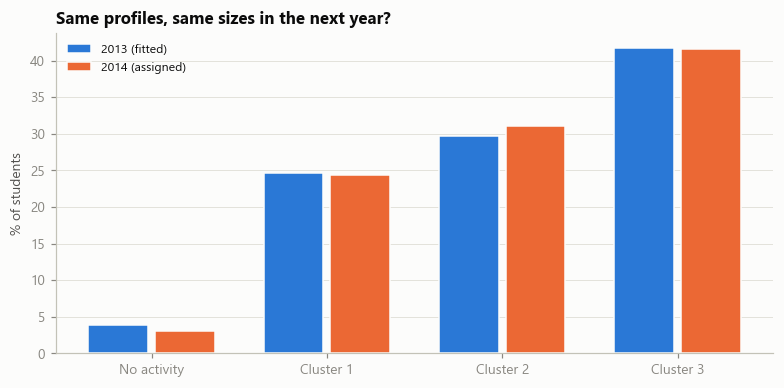

In [17]:
assign_all = pd.concat([asg_tr, asg_te], ignore_index=True)
assign_all["year"] = np.where(assign_all.split == "train", 2013, 2014)
share = pd.crosstab(assign_all.year, assign_all.cluster, normalize="index").mul(100).round(1)
share.columns = ["No activity" if c == 0 else f"Cluster {c}" for c in share.columns]
print("share of students in each profile (%):"); display(share)
p13, p14 = [pd.crosstab(assign_all.year, assign_all.cluster, normalize="index").loc[y].values for y in (2013, 2014)]
psi = float(np.sum((p14 - p13) * np.log((p14 + 1e-9) / (p13 + 1e-9))))
print(f"population stability index 2013 vs 2014: {psi:.3f} (below 0.1 is usually read as no meaningful shift)")
print(f"mean posterior certainty of the assignment: 2013 {asg_tr.max_posterior.mean():.3f} | 2014 {asg_te.max_posterior.mean():.3f}")

by_mod = pd.crosstab(assign_all.merge(feat[KEY], on=KEY).code_module, assign_all.cluster, normalize="index").mul(100).round(1)
by_mod.columns = ["No activity" if c == 0 else f"Cluster {c}" for c in by_mod.columns]
print("\nprofile shares by module, both years (%); CCC exists only in 2014:"); display(by_mod)

fig, ax = plt.subplots(figsize=(7.2, 3.6))
cols = list(share.columns); x = np.arange(len(cols)); w = 0.38
ax.bar(x - w / 2, share.loc[2013], width=w - 0.04, color=C1, edgecolor=SURFACE, label="2013 (fitted)")
ax.bar(x + w / 2, share.loc[2014], width=w - 0.04, color=C2, edgecolor=SURFACE, label="2014 (assigned)")
ax.set_xticks(x, cols); ax.set_ylabel("% of students"); ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=8)
ax.set_title("Same profiles, same sizes in the next year?")
fig.tight_layout(); savefig(fig, "05_cohort_shares.png"); plt.show()

**Observed (features only, no 2014 labels).** The profile shares are practically identical in the two years: 24.7 / 29.7 / 41.7% in 2013 and 24.3 / 31.1 / 41.6% in 2014 (population stability index 0.002, far below the 0.1 level), and the mean assignment certainty is the same (0.852 vs 0.851). Module CCC, never seen in training, is spread over the profiles in a similar way (20.5 / 36.9 / 40.6%), and the other modules differ only modestly (for example EEE has few low-engagement students, 11.8%).
**Why it matters.** The profile definition transfers to a new cohort and to an unseen module, which is the payoff of building every feature relative to the module-presentation.
**Caution.** Ranks within a module make the profile shares similar across modules by construction, so these profiles cannot be used to compare absolute engagement between modules.

## 7. Visual check and saving

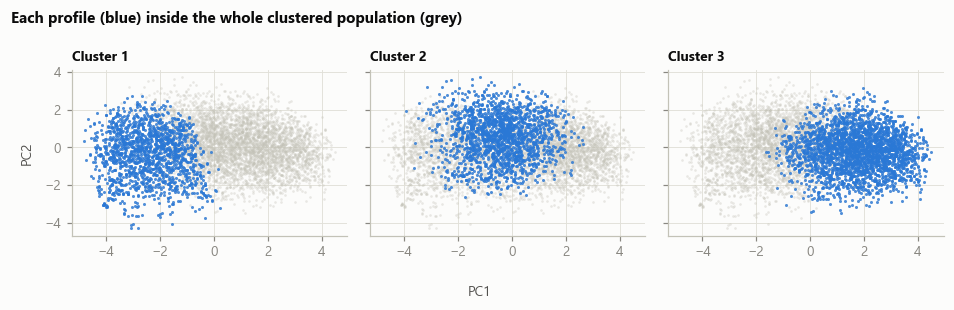

In [18]:
Z2 = Z[:, :2]; rs2 = np.random.RandomState(RANDOM_STATE); show = rs2.choice(len(Z2), size=min(6000, len(Z2)), replace=False)
ncol = min(K, 4); nrow = int(np.ceil(K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.9 * ncol, 2.7 * nrow), sharex=True, sharey=True, squeeze=False)
for j, ax in enumerate(axes.ravel()):
    if j >= K: ax.axis("off"); continue
    ax.scatter(Z2[show, 0], Z2[show, 1], s=3, color=AXIS, alpha=0.35, linewidths=0)
    mk = fit_df.cluster.values[show] == j + 1
    ax.scatter(Z2[show][mk, 0], Z2[show][mk, 1], s=4, color=C1, alpha=0.8, linewidths=0)
    ax.set_title(f"Cluster {j + 1}", fontsize=9)
fig.supxlabel("PC1", fontsize=9, color=INK2); fig.supylabel("PC2", fontsize=9, color=INK2)
fig.suptitle("Each profile (blue) inside the whole clustered population (grey)", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout(); savefig(fig, "05_cluster_scatter.png"); plt.show()

In [19]:
out = assign_all[KEY + ["split", "cluster", "max_posterior"] + [f"p_c{j + 1}" for j in range(K)]]
out.to_csv(PROC / "oulad_clusters_day28.csv", index=False)
prof_out = orig.join(ass[["n", "share_of_clustered", "submit_rate_early", "score_pct_mean", "edu_level", "imd_order"]]).join(risk[["rate"]].rename(columns={"rate": "at_risk_rate"}))
prof_out.to_csv(OUT / "cluster_profiles.csv")
sel.to_csv(OUT / "cluster_k_selection.csv"); bic.to_csv(OUT / "cluster_gmm_bic.csv"); dbs.to_csv(OUT / "cluster_dbscan_grid.csv")
(OUT / "cluster_model.json").write_text(json.dumps({"k": K, "features": CL_FEATS, "pca_components": int(pca.n_components_), "covariance_type": "full",
                                                    "fit_students": int(len(fit_df)), "random_state": RANDOM_STATE}, indent=2))
print("saved", PROC / "oulad_clusters_day28.csv", out.shape)

saved ..\data\processed\oulad_clusters_day28.csv (27553, 9)


**Observed.** In the plot of the first two principal components the active students form one connected cloud. Each profile is a slice along the main axis (PC1, overall volume and regularity), overlapping its neighbours, which matches the weak silhouettes, the missing DBSCAN gaps and the method disagreement.

## 8. Synthesis (RQ2)

**Do distinct engagement profiles exist at day 28?** Partly. There are three interpretable and reproducible *regions* of a continuum (low, intermittent and sustained engagement) plus a small group with no activity at all. They are **not** natural, well-separated student types: silhouettes are under 0.25, DBSCAN finds no density gaps, and different methods draw different boundaries.

**Do their risks differ?** Strongly and consistently. At-risk rates are 80.7% (no activity), 62.7%, 46.5% and 28.8%; the profile effect holds after controlling for the module (odds ratios 4.2 and 2.2 against the sustained profile), and the deprivation gradient remains inside each profile.

**Are they stable?** Yes, across years (PSI 0.002) and for an unseen module, but only because every feature was ranked within its module-presentation. Clusters built on raw behaviours mostly recovered the modules (Cramer's V 0.52) and drifted heavily.

**What they are good for.** Communication and targeting (a simple three-level plus no-activity scheme). They add no predictive information beyond the selected features, so they are not model inputs.

**Limits.** The structure is weak, so the number of profiles is partly a convenience choice (the rule left a single candidate). The risk rates are 2013 training-year numbers; the 2014 risk by profile is deferred to notebook 07 so the test labels stay untouched until the final evaluation. Results describe association.

**Carried forward**

| Notebook | Use |
|---|---|
| 06 association rules and categorical analysis | Use the engagement profile (no activity, low, intermittent, sustained) as one categorical item next to education, deprivation, disability and age band; look for combinations with unusually high or low risk |
| 07 modelling and drift | Do not use cluster features in models; report 2014 at-risk rate by profile once, as a descriptive result; keep the per-module and unseen-module (CCC) analysis |